In [1]:
#ok i'm tired of waiting for sebastiaan to fix his code so i'm just gonna figure out how generate the exact grid i need
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

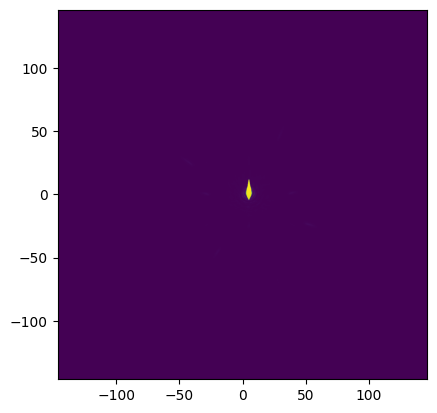

In [2]:
#upload an image that i know has the right grid (units of lam/d at ha)
field = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/20240315-selected/isat_image_cube.fits')[0]
imshow_field(field)

In [3]:
type(field.grid)
field.grid.regular_coords

(array([0.28571429, 0.28571429]),
 array([1024, 1024]),
 array([-146.14285714, -146.14285714]))

In [4]:
extent = 512 * 6/21
pgrid = make_pupil_grid(512,2*extent)

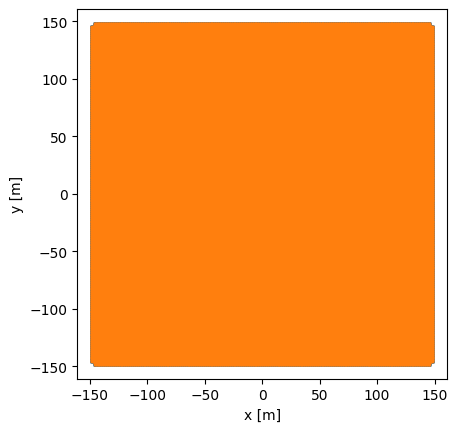

In [5]:
#grab the code from the website that lets you plot grids so i can make sure my generated grid is the same
grid = make_pupil_grid(512)

plt.plot(field.grid.x, field.grid.y, '+')
plt.gca().set_aspect(1)
plt.xlabel('x [m]')
plt.ylabel('y [m]')

plt.plot(pgrid.x, pgrid.y, '+')
plt.gca().set_aspect(1)
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()
#nice.

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:23: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


angles in image: [ 90.         -88.09840524 178.66778701 -87.6714883 ]
pair offsets: [-88.66778701  -0.42691694]
calculated command: 89.09470395234158


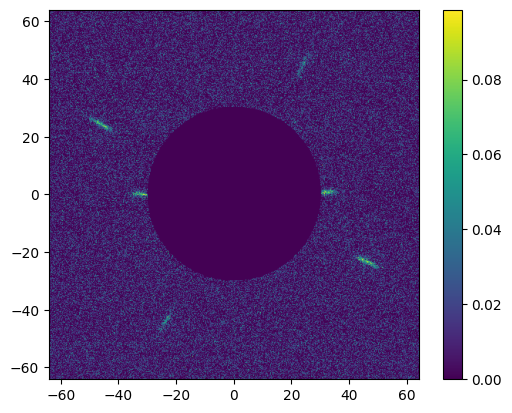

In [10]:
#then testing it out here
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,ncpc=False,snr_threshold=3.1) 

field =  read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/sparkles_sweep.fits')[1000]
filtered = ADC.crop_image(field,extent=480)

imshow_field(filtered)
plt.colorbar()
a = ADC.all_speckle_angles(filtered)
print(f'angles in image: {a}')

pairs = ADC.speckle_pairs(a)
command = np.squeeze(ADC.calculate_command(pairs))
print(f'pair offsets: {pairs}')
print(f'calculated command: {command}')